In [1]:
import sys
sys.path.append("../..")

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib
import os
from surgeNN import io
import gcsfs
fs = gcsfs.GCSFileSystem() #list stores, stripp zarr from filename, load 

In [2]:
from surgeNN import evaluation
p = np.arange(0.1,1.1,.05)
r = np.arange(0.1,1.1,.05)
[P,R] = np.meshgrid(p,r)
f1_contours = evaluation.compute_f1(P,R)

In [4]:
#configure the script
tg        = 'esbjerg-esb-dnk-dmi.csv'#'brest-822a-fra-uhslc.csv'#
max_timesteps_between_extremes = 3

#folders = [['/home/jovyan/surgeNN/results/nns/sensitivity_tests/msl_u_v/performance/lstm',
#            ]]

folders = [['/home/jovyan/surgeNN/results/nns/CMCC-CM2-VHR4/by_years/1980_2017_seed0/performance/lstm',
            '/home/jovyan/surgeNN/results/nns/CMCC-CM2-VHR4/by_years/1980_2017_seed1/performance/lstm',
            '/home/jovyan/surgeNN/results/nns/CMCC-CM2-VHR4/by_years/1980_2017_seed2/performance/lstm',
            '/home/jovyan/surgeNN/results/nns/CMCC-CM2-VHR4/by_years/1980_2017_seed3/performance/lstm',
            '/home/jovyan/surgeNN/results/nns/CMCC-CM2-VHR4/by_years/1980_2017_seed4/performance/lstm',
            ]]
models = ['lstm']

labels = ['0','1','2','3','4']

model_datasets={}
for m,model in enumerate(models):
    datasets=[]
    for folder in folders[m]:
        dir_name = folder

        ds =io.Output(dir_name)
        ds.open_performance_data([tg])
        ds.data = ds.data.sel(max_timesteps_between_extremes=max_timesteps_between_extremes).load()

        observed_thresholds = ds.observed_thresholds()
        ds = ds.data
        ds['observed_thresholds'] = observed_thresholds
        datasets.append(ds)

    '''
    ds = xr.concat(datasets,dim='test',coords='different')
    ds['test'] = folders[m]
    
    model_datasets[model] = ds
    '''
    
codec = xr.open_dataset('/home/jovyan/surgeNN/results/gtsm/CoDEC_ERA5_at_gesla3_tgs_eu_performance.nc')


where_observed_peaks = (datasets[0].o.isel(it=0)>=observed_thresholds)
if max_timesteps_between_extremes>0:
    where_observed_peaks = ((where_observed_peaks) & (where_observed_peaks.rolling(time=1+2*int(max_timesteps_between_extremes),center='True').sum()>1)) #from 'compute_statistics_on_output_ds'\n",

In [5]:
ds_all = xr.concat(datasets,dim='seed')

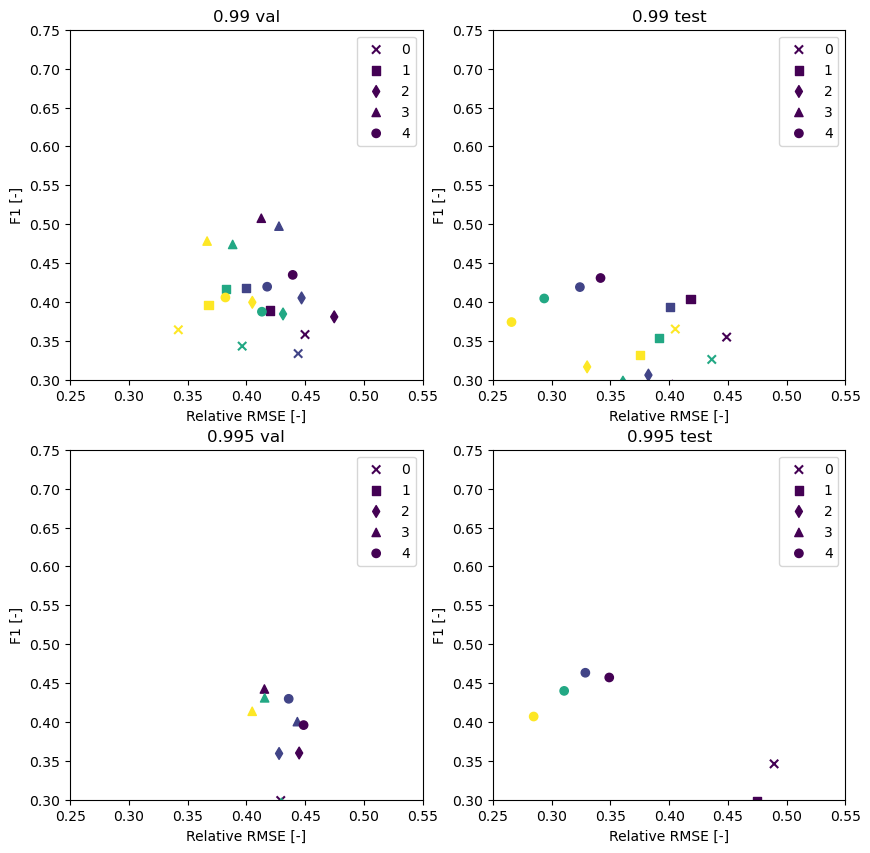

In [6]:
fig = plt.figure(figsize=(10,10))
quantile=.99
split='val'
ax = fig.add_subplot(221)

for seed in np.arange(5):
    ax.scatter(ds_all.isel(seed=seed).rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.isel(seed=seed).sel(quantile=quantile,split=split).isel(tg=0),
                ds_all.isel(seed=seed).f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it'),c=ds_all.isel(seed=seed).hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha').mean(dim='it'),label=str(seed),marker=['x','s','d','^','o'][seed])


ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.75])
ax.set_xlim([.25,.55])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()


quantile=.99
split='test'
ax = fig.add_subplot(222)

for seed in np.arange(5):
    ax.scatter(ds_all.isel(seed=seed).rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.isel(seed=seed).sel(quantile=quantile,split=split).isel(tg=0),
                ds_all.isel(seed=seed).f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it'),c=ds_all.isel(seed=seed).hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha').mean(dim='it'),label=str(seed),marker=['x','s','d','^','o'][seed])


ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.75])
ax.set_xlim([.25,.55])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()



quantile=.995
split='val'
ax = fig.add_subplot(223)

for seed in np.arange(5):
    ax.scatter(ds_all.isel(seed=seed).rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.isel(seed=seed).sel(quantile=quantile,split=split).isel(tg=0),
                ds_all.isel(seed=seed).f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it'),c=ds_all.isel(seed=seed).hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha').mean(dim='it'),label=str(seed),marker=['x','s','d','^','o'][seed])


ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.75])
ax.set_xlim([.25,.55])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()


quantile=.995
split='test'
ax = fig.add_subplot(224)

for seed in np.arange(5):
    ax.scatter(ds_all.isel(seed=seed).rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.isel(seed=seed).sel(quantile=quantile,split=split).isel(tg=0),
                ds_all.isel(seed=seed).f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it'),c=ds_all.isel(seed=seed).hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha').mean(dim='it'),label=str(seed),marker=['x','s','d','^','o'][seed])


ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.75])
ax.set_xlim([.25,.55])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()

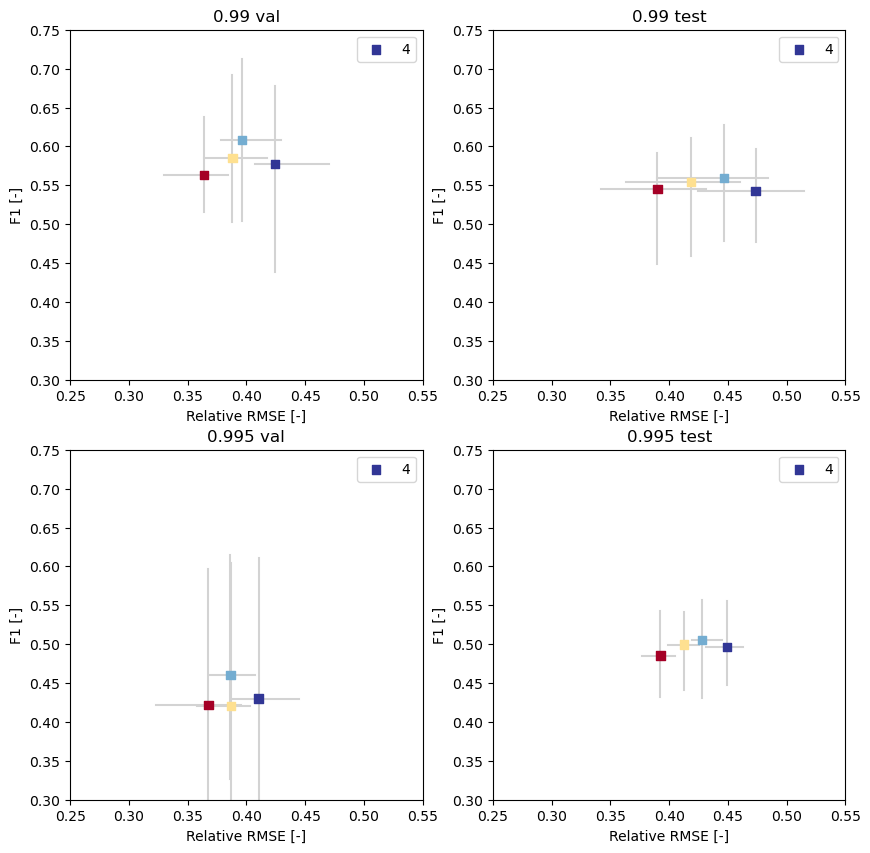

In [33]:
alpha_cmap = plt.get_cmap('RdYlBu_r', 6) #alpha colormap

fig = plt.figure(figsize=(10,10))
quantile=.99
split='val'
ax = fig.add_subplot(221)


ax.scatter((ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),
            ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed'),c=ds_all.hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha').mean(dim='it').mean(dim='seed'),
           cmap=alpha_cmap,label=str(seed),marker='s',zorder=5)

ax.plot([(ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).max(dim='seed'),
         (ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).min(dim='seed'),],
       [ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed'),ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed')],color='lightgrey')


ax.plot([(ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),
         (ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),],
       [ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').min(dim='seed'),ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').max(dim='seed')],color='lightgrey')

ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.75])
ax.set_xlim([.25,.55])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()


quantile=.99
split='test'
ax = fig.add_subplot(222)
ax.scatter((ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),
            ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed'),c=ds_all.hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha').mean(dim='it').mean(dim='seed'),
           cmap=alpha_cmap,label=str(seed),marker='s',zorder=5)

ax.plot([(ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).max(dim='seed'),
         (ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).min(dim='seed'),],
       [ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed'),ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed')],color='lightgrey')


ax.plot([(ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),
         (ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),],
       [ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').min(dim='seed'),ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').max(dim='seed')],color='lightgrey')

ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.75])
ax.set_xlim([.25,.55])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()



quantile=.995
split='val'
ax = fig.add_subplot(223)
ax.scatter((ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),
            ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed'),c=ds_all.hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha').mean(dim='it').mean(dim='seed'),
           cmap=alpha_cmap,label=str(seed),marker='s',zorder=5)

ax.plot([(ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).max(dim='seed'),
         (ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).min(dim='seed'),],
       [ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed'),ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed')],color='lightgrey')


ax.plot([(ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),
         (ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),],
       [ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').min(dim='seed'),ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').max(dim='seed')],color='lightgrey')


ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.75])
ax.set_xlim([.25,.55])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()


quantile=.995
split='test'
ax = fig.add_subplot(224)

ax.scatter((ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),
            ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed'),c=ds_all.hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha').mean(dim='it').mean(dim='seed'),
           cmap=alpha_cmap,label=str(seed),marker='s',zorder=5)

ax.plot([(ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).max(dim='seed'),
         (ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).min(dim='seed'),],
       [ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed'),ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').mean(dim='seed')],color='lightgrey')


ax.plot([(ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),
         (ds_all.rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it')/ds_all.observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0)).mean(dim='seed'),],
       [ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').min(dim='seed'),ds_all.f1.sel(split=split,quantile=quantile).isel(tg=0).mean(dim='it').max(dim='seed')],color='lightgrey')

ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.75])
ax.set_xlim([.25,.55])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()

Text(0.5, 0, 'Relative RMSE [-]')

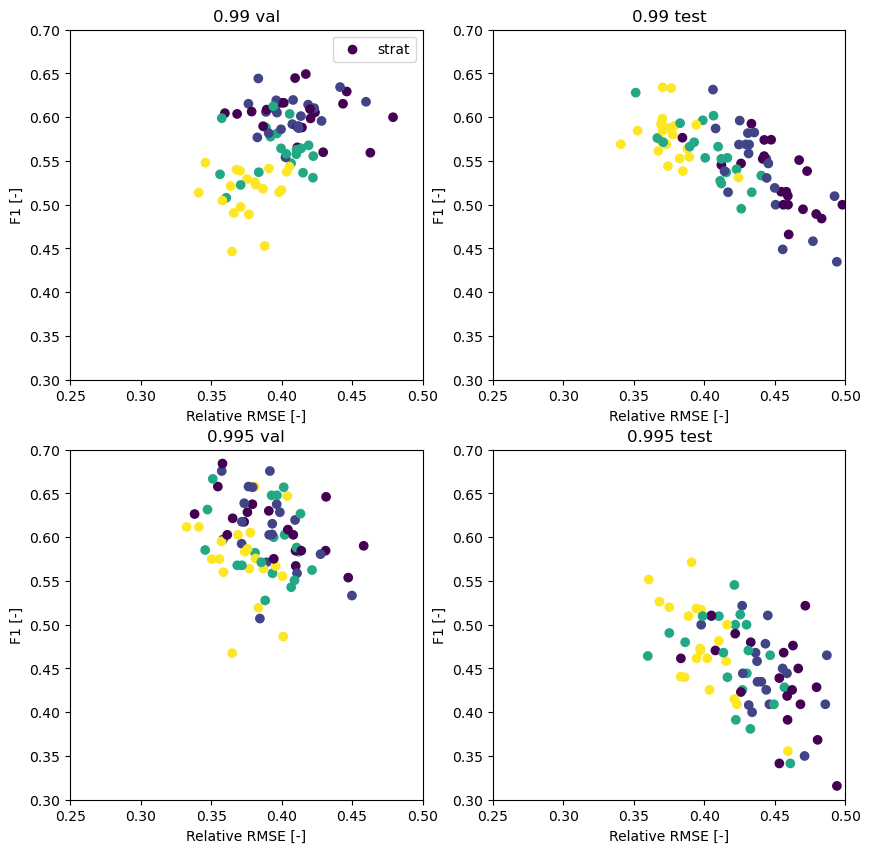

In [6]:
fig = plt.figure(figsize=(10,10))
quantile=.99
split='val'
ax = fig.add_subplot(221)
'''
ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])
'''
ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])


ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_ylim([.3,.7])
ax.set_xlim([.25,.5])
ax.set_xlabel('Relative RMSE [-]')
ax.legend()


quantile=.99
split='test'
ax = fig.add_subplot(222)
'''
ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])
'''
ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.set_ylim([.3,.7])
ax.set_xlim([.25,.5])
ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')



quantile=.995
split='val'
ax = fig.add_subplot(223)
'''
ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])
'''
ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.set_ylim([.3,.7])
ax.set_xlim([.25,.5])
ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')


quantile=.995
split='test'
ax = fig.add_subplot(224)
'''
ax.scatter(datasets[2].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[2].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[1].f1.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])
'''
ax.scatter(datasets[0].rmse_extremes.sel(split=split,quantile=quantile).isel(tg=0)/observed_thresholds.sel(quantile=quantile,split=split).isel(tg=0),
            datasets[0].f1.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.set_ylim([.3,.7])
ax.set_xlim([.25,.5])
ax.set_title(str(quantile) +' '+str(split))
ax.set_ylabel('F1 [-]')
ax.set_xlabel('Relative RMSE [-]')

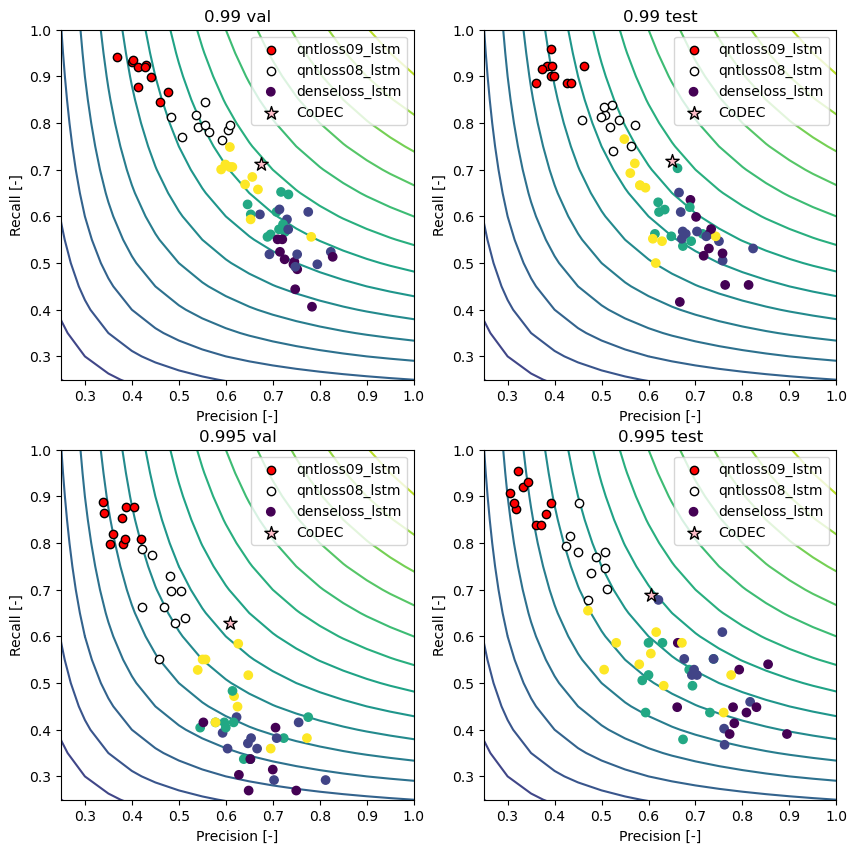

In [5]:
fig = plt.figure(figsize=(10,10))
quantile=.99
split='val'
ax = fig.add_subplot(221)

ax.scatter(datasets[2].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[2].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])

ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()


quantile=.99
split='test'
ax = fig.add_subplot(222)

ax.scatter(datasets[2].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[2].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()


quantile=.995
split='val'
ax = fig.add_subplot(223)

ax.scatter(datasets[2].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[2].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()


quantile=.995
split='test'
ax = fig.add_subplot(224)

ax.scatter(datasets[2].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[2].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='red',edgecolor='black',label=labels[2])

ax.scatter(datasets[1].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[1].recall.sel(split=split,quantile=quantile).isel(tg=0),facecolor='white',edgecolor='black',label=labels[1])

ax.scatter(datasets[0].precision.sel(split=split,quantile=quantile).isel(tg=0),
            datasets[0].recall.sel(split=split,quantile=quantile).isel(tg=0),c=datasets[0].hyperparameters.sel(split=split).isel(tg=0).sel(p='dl_alpha'),label=labels[0])
ax.scatter(codec.precision.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),
                                      codec.recall.sel(split=split,quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv'),marker='*',facecolor='pink',edgecolor='black',s=100,label='CoDEC')
ax.contour(P,R,f1_contours,levels=20,zorder=0)
ax.set_title(str(quantile) +' '+str(split))
ax.set_xlabel('Precision [-]')
ax.set_ylabel('Recall [-]')
ax.set_xlim([.25,1])
ax.set_ylim([.25,1])
ax.legend()

ValueError: x and y must be the same size

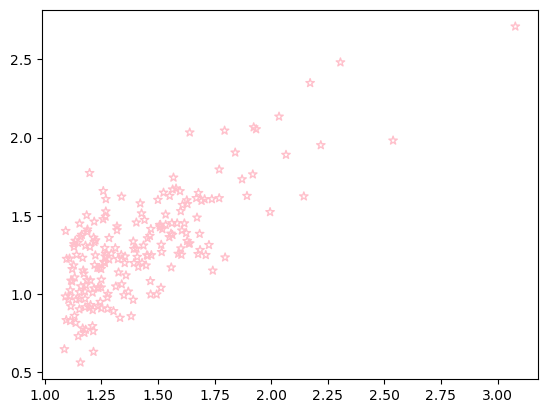

In [13]:
#plot predictions of models with lowest rmse in val split (99.5p)
plt.scatter(datasets[0].sel(split='test',quantile=.99,tg='esbjerg-esb-dnk-dmi.csv').where(where_observed_peaks.sel(split='test',tg='esbjerg-esb-dnk-dmi.csv',quantile=.99),drop=True).o.isel(it=-1),
            codec.isel(max_timesteps_between_extremes=0,drop=True).sel(split='test',quantile=quantile,tg='esbjerg-esb-dnk-dmi.csv').where(where_observed_peaks.isel(split=2,tg=0).sel(quantile=.99),drop=True).surge,
           facecolor='None',edgecolor='grey',label='codec',zorder=1,marker='d')

plt.scatter(datasets[0].sel(split='test',quantile=.99,tg='esbjerg-esb-dnk-dmi.csv').where(where_observed_peaks.sel(split='test',tg='esbjerg-esb-dnk-dmi.csv',quantile=.99),drop=True).o.isel(it=-1),
            datasets[0].sel(split='test',quantile=.99,tg='esbjerg-esb-dnk-dmi.csv').where(where_observed_peaks.sel(split='test',tg='esbjerg-esb-dnk-dmi.csv',quantile=.99),drop=True).yhat.isel(it=3),
           facecolor='None',edgecolor='blue',label=labels[0],zorder=0)

plt.scatter(datasets[0].sel(split='test',quantile=.99,tg='esbjerg-esb-dnk-dmi.csv').where(where_observed_peaks.sel(split='test',tg='esbjerg-esb-dnk-dmi.csv',quantile=.99),drop=True).o.isel(it=-1),
            datasets[2].sel(split='test',quantile=.99,tg='esbjerg-esb-dnk-dmi.csv').where(where_observed_peaks.sel(split='test',tg='esbjerg-esb-dnk-dmi.csv',quantile=.99),drop=True).yhat.isel(it=4),
           facecolor='None',edgecolor='green',label=labels[2],zorder=2)
plt.plot([.6,3.5],[.6,3.5])
plt.xlim(.6,3.5)
plt.xlabel('obs')
plt.ylim(.6,3.5)
plt.ylabel('yhat')
plt.legend()